<a href="https://colab.research.google.com/github/nagireddi-yashaswini/quantum-computing-hacakthon/blob/main/Q_43.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# Quantum Neural Networks in Generative Learning

This notebook demonstrates how a Quantum Neural Network (specifically, a **Quantum Circuit Born Machine (QCBM)**) can be trained to learn and generate a simple probability distribution. We will focus on the **2x2 Bars and Stripes (BAS)** dataset, which is a standard benchmark in quantum generative modeling inspired by classical pattern learning.

### References
- Tian, J., et al. (2023). "Recent Advances for Quantum Neural Networks in Generative Learning". *IEEE Transactions on Pattern Analysis and Machine Intelligence*.
```

```markdown
## Step 1: Install Required Libraries
First, we install `qiskit` and `qiskit-aer` for designing and simulating the quantum circuits, as well as `scipy` for classical optimization.

In [ ]:
!pip install qiskit qiskit-aer pylatexenc matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 24.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 46.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 21.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-aer]


```markdown
## Step 2: Import Dependencies
We import standard numerical libraries, visualization tools, and Qiskit SDK components.

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Qiskit imports
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

print("Setup completed successfully.")

Setup completed successfully.


```markdown
## Step 3: Define and Visualize the 2x2 Bars and Stripes Dataset
For a 2x2 grid, there are 4 pixels. A pattern is "Bars or Stripes" if all rows are uniform, or all columns are uniform. There are 6 valid patterns out of $2^4 = 16$ total possibilities:
- All white (0000)
- All black (1111)
- Horizontal bars (1100, 0011)
- Vertical stripes (1010, 0101)

We will define the target probability distribution as a uniform distribution over these 6 valid states, with 0 probability for the remaining 10 invalid states.

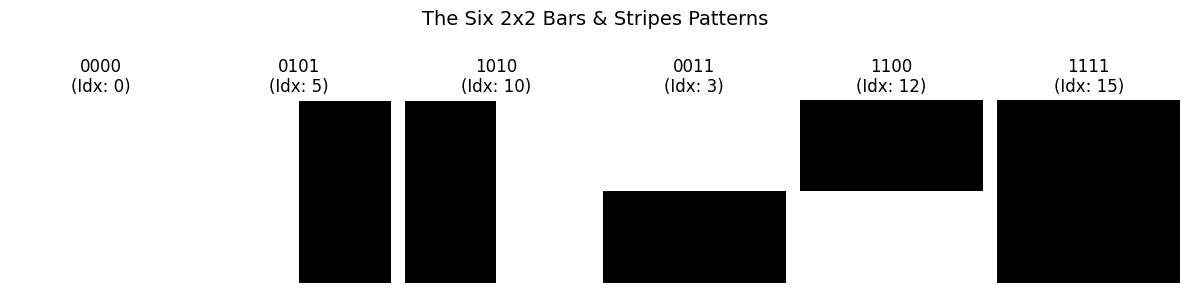

In [ ]:
# 2x2 patterns mapped to decimal values corresponding to their binary representations
# index ordering: pixel 0 (top-left), pixel 1 (top-right), pixel 2 (bottom-left), pixel 3 (bottom-right)
# Binary: [p0, p1, p2, p3]
bas_patterns = {
    "0000": 0,
    "0101": 5,
    "1010": 10,
    "0011": 3,
    "1100": 12,
    "1111": 15
}

# Target probability distribution
target_distribution = np.zeros(16)
for val in bas_patterns.values():
    target_distribution[val] = 1.0 / len(bas_patterns)

# Plot the 6 valid patterns
fig, axes = plt.subplots(1, 6, figsize=(12, 3))
for i, (bin_str, val) in enumerate(bas_patterns.items()):
    grid = np.array([int(char) for char in bin_str]).reshape(2, 2)
    axes[i].imshow(grid, cmap='gray_r', vmin=0, vmax=1)
    axes[i].set_title(f"{bin_str}\n(Idx: {val})")
    axes[i].axis('off')
plt.suptitle("The Six 2x2 Bars & Stripes Patterns", y=1.05, fontsize=14)
plt.tight_layout()
plt.show()

```markdown
## Step 4: Create the Parameterized Quantum Circuit (QNN)
We construct a variational quantum circuit using 4 qubits. Each layer consists of parameterized single-qubit rotations ($R_Y$ and $R_Z$) followed by a chain of $CNOT$ gates to generate entanglement. We can adjust the number of repeating layers to scale the model capacity.

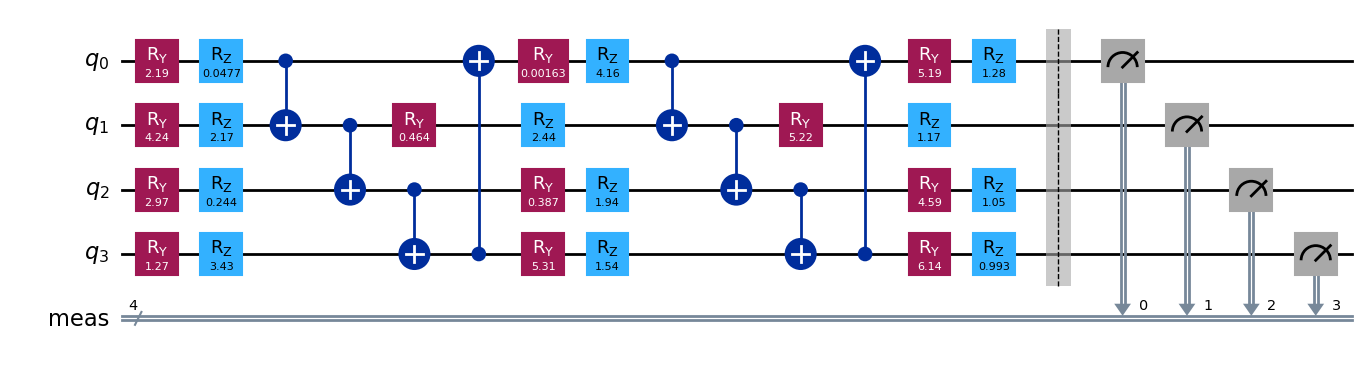

In [ ]:
def build_qnn_circuit(parameters, num_qubits=4, layers=2):
    """
    Builds a parameterized quantum circuit (QCBM architecture).
    parameters: flat 1D numpy array of angles
    """
    qc = QuantumCircuit(num_qubits)
    param_idx = 0

    # Initial rotation layer
    for i in range(num_qubits):
        qc.ry(parameters[param_idx], i)
        qc.rz(parameters[param_idx+1], i)
        param_idx += 2

    # Repetitive layers containing entanglement and rotation
    for layer in range(layers):
        # Entanglement layer (linear CNOT chain)
        for i in range(num_qubits - 1):
            qc.cx(i, i+1)
        qc.cx(num_qubits - 1, 0) # Periodic boundary connection

        # Rotations after entanglement
        for i in range(num_qubits):
            qc.ry(parameters[param_idx], i)
            qc.rz(parameters[param_idx+1], i)
            param_idx += 2

    qc.measure_all()
    return qc

# Let's visualize an example circuit with 2 layers
num_qubits = 4
layers = 2
# Total parameters required: (num_qubits * 2) * (layers + 1)
num_params = num_qubits * 2 * (layers + 1)
test_params = np.random.uniform(0, 2*np.pi, num_params)

example_circuit = build_qnn_circuit(test_params, num_qubits=num_qubits, layers=layers)
example_circuit.draw(output='mpl')

```markdown
## Step 5: Sampling and Probability Estimation
We set up a helper function to run the quantum circuit on the simulator and estimate the probability of each of the 16 standard states.

In [ ]:
simulator = AerSimulator()

def get_probability_distribution(parameters, num_qubits=4, layers=2, shots=10000):
    qc = build_qnn_circuit(parameters, num_qubits, layers)

    # Run circuit
    result = simulator.run(qc, shots=shots).result()
    counts = result.get_counts()

    # Convert counts to probability distribution vector of size 2^num_qubits
    probabilities = np.zeros(2**num_qubits)
    for state_str, count in counts.items():
        # Qiskit uses reverse order for bits, we reverse it to match standard representation
        state_idx = int(state_str, 2)
        probabilities[state_idx] = count / shots
    return probabilities

# Test distribution generation
test_dist = get_probability_distribution(test_params, layers=layers)
print("Generated Distribution Example:\n", np.round(test_dist, 3))

Generated Distribution Example:
 [0.152 0.031 0.035 0.094 0.026 0.044 0.178 0.011 0.011 0.037 0.099 0.024
 0.04  0.073 0.069 0.077]


```markdown
## Step 6: Define Evaluation Metrics (KL Divergence & MMD)
We need objective functions to compare the target distribution ($P$) against the generated distribution ($Q$).
1. **Kullback-Leibler (KL) Divergence**: Measures similarity between two distributions. To avoid infinity errors when $Q(x)=0$, we add a minor epsilon smoothing factor.
2. **Maximum Mean Discrepancy (MMD)**: A distance metric based on kernel methods.

In [ ]:
def kl_divergence(p, q, eps=1e-10):
    # Apply epsilon smoothing to prevent divide-by-zero or log of zero errors
    p_smooth = np.clip(p, eps, 1.0)
    q_smooth = np.clip(q, eps, 1.0)
    return np.sum(p_smooth * np.log(p_smooth / q_smooth))

def gaussian_kernel(x, y, sigma=0.25):
    return np.exp(-np.linalg.norm(x - y)**2 / (2 * sigma**2))

def maximum_mean_discrepancy(p, q):
    """Calculates MMD between two discrete probability vectors."""
    n = len(p)
    states = np.array([[int(b) for b in format(i, '04b')] for i in range(n)])

    # Precompute kernel matrix
    K = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            K[i, j] = gaussian_kernel(states[i], states[j])

    # Compute MMD formula using probability weights
    term_pp = np.dot(p, np.dot(K, p))
    term_qq = np.dot(q, np.dot(K, q))
    term_pq = np.dot(p, np.dot(K, q))

    return term_pp + term_qq - 2 * term_pq

```markdown
## Step 7: Train the Quantum Neural Network
Using `scipy.optimize.minimize`, we optimize the parameters of the quantum circuit to minimize the distance to our target distribution. We will track execution metrics such as total evaluations and training time.

In [ ]:
# Configuration parameters
num_qubits = 4
layers = 2
shots = 5000
num_params = num_qubits * 2 * (layers + 1)

# Keep track of metrics
loss_history = []
circuit_evaluations = 0

def loss_function(parameters):
    global circuit_evaluations
    circuit_evaluations += 1

    # Generate probability distribution
    gen_dist = get_probability_distribution(parameters, num_qubits, layers, shots)

    # Minimize distance from the target using KL divergence
    loss = kl_divergence(target_distribution, gen_dist)
    loss_history.append(loss)
    return loss

# Initialize weights randomly
np.random.seed(42)
initial_parameters = np.random.uniform(0, 2*np.pi, num_params)

print("Starting training of Quantum Neural Network...")
start_time = time.time()

# COBYLA is a non-gradient optimizer ideal for noisy simulations
opt_result = minimize(
    loss_function,
    initial_parameters,
    method='COBYLA',
    options={'maxiter': 100}
)

training_time = time.time() - start_time
optimized_params = opt_result.x

print(f"Training complete in {training_time:.2f} seconds.")

Starting training of Quantum Neural Network...
Training complete in 4.33 seconds.


```markdown
## Step 8: Inference and Evaluation
We now use the optimized parameter set to generate a final set of samples, and compute our metrics.

In [ ]:
inference_start = time.time()
final_generated_distribution = get_probability_distribution(optimized_params, num_qubits, layers, shots)
inference_time = time.time() - inference_start

# Compute final evaluation metrics
final_kl = kl_divergence(target_distribution, final_generated_distribution)
final_mmd = maximum_mean_discrepancy(target_distribution, final_generated_distribution)
circuit_depth = example_circuit.depth()

```markdown
## Step 9: Visualizations
We plot the loss curve over classical optimization iterations and compare the target distribution directly against our model's generated distribution.

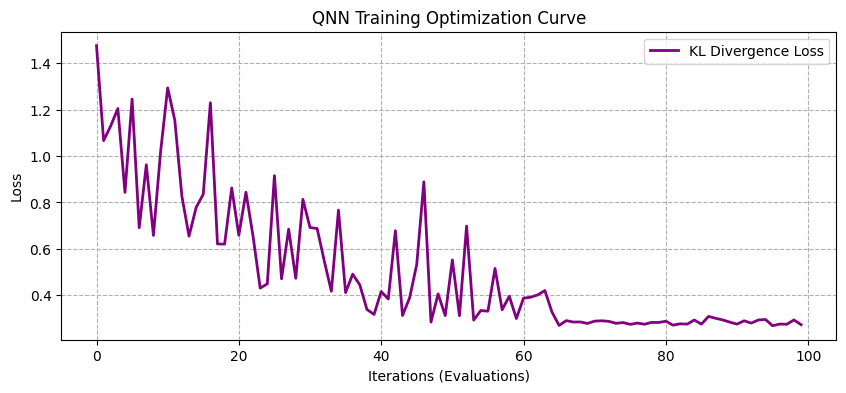

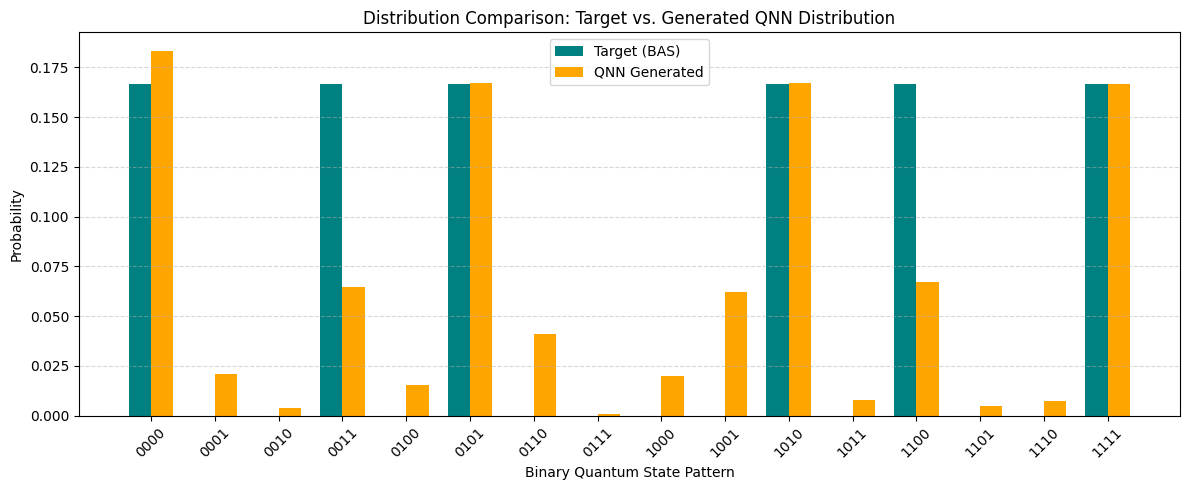

In [ ]:
# 1. Plot Loss history
plt.figure(figsize=(10, 4))
plt.plot(loss_history, label='KL Divergence Loss', color='purple', lw=2)
plt.title("QNN Training Optimization Curve")
plt.xlabel("Iterations (Evaluations)")
plt.ylabel("Loss")
plt.grid(True, linestyle='--')
plt.legend()
plt.show()

# 2. Compare Target vs Generated distribution
states_labels = [format(i, '04b') for i in range(16)]

plt.figure(figsize=(12, 5))
x = np.arange(16)
width = 0.35

plt.bar(x - width/2, target_distribution, width, label='Target (BAS)', color='teal')
plt.bar(x + width/2, final_generated_distribution, width, label='QNN Generated', color='orange')

plt.xlabel('Binary Quantum State Pattern')
plt.ylabel('Probability')
plt.title('Distribution Comparison: Target vs. Generated QNN Distribution')
plt.xticks(x, states_labels, rotation=45)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

```markdown
## Step 10: Final Project Summary
Lastly, we print a comprehensive final status report outlining both the algorithmic success and the quantum computational complexity metrics.

In [ ]:
print("="*50)
print("     QNN GENERATIVE LEARNING SUMMARY REPORT      ")
print("="*50)
print(f"{'- MODEL PERFORMANCE -':<30}")
print(f"Final KL Divergence:         {final_kl:.5f}")
print(f"Final MMD Score:             {final_mmd:.5f}")
print("")
print(f"{'- QUANTUM RESOURCE COSTS -':<30}")
print(f"Number of Qubits:            {num_qubits}")
print(f"Circuit Depth:               {circuit_depth}")
print(f"Number of Shots per Run:     {shots}")
print(f"Total Circuit Evaluations:   {circuit_evaluations}")
print("")
print(f"{'- EXECUTION TIMES -':<30}")
print(f"Training Time:               {training_time:.2f} seconds")
print(f"Generation/Inference Time:   {inference_time:.4f} seconds")
print("="*50)

     QNN GENERATIVE LEARNING SUMMARY REPORT      
- MODEL PERFORMANCE -         
Final KL Divergence:         0.29259
Final MMD Score:             0.02735

- QUANTUM RESOURCE COSTS -    
Number of Qubits:            4
Circuit Depth:               15
Number of Shots per Run:     5000
Total Circuit Evaluations:   100

- EXECUTION TIMES -           
Training Time:               4.33 seconds
Generation/Inference Time:   0.0213 seconds
